In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import zipfile
import io

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", 50)

In [2]:
# Step 1: Upload your dataset from your computer
uploaded = files.upload()

# Keep the uploaded file name and its contents
file_name = list(uploaded.keys())[0]
file_content = uploaded[file_name]

print("Uploaded file:", file_name)

Saving india_air_quality_sample_50000 (1).zip to india_air_quality_sample_50000 (1).zip
Uploaded file: india_air_quality_sample_50000 (1).zip


In [4]:
# Step 2: Read the uploaded file
if file_name.lower().endswith(".zip"):
    # If the uploaded file is a ZIP, find the CSV file inside it
    with zipfile.ZipFile(io.BytesIO(file_content), "r") as zip_file:
        csv_names = [name for name in zip_file.namelist() if name.lower().endswith(".csv")]

        if len(csv_names) == 0:
            raise ValueError("The ZIP file does not contain a CSV file.")

        with zip_file.open(csv_names[0]) as csv_file:
            df = pd.read_csv(csv_file, encoding="latin1", low_memory=False)

elif file_name.lower().endswith(".csv"):
    # If the uploaded file is already a CSV, read it directly
    df = pd.read_csv(io.BytesIO(file_content), encoding="latin1", low_memory=False)

else:
    raise ValueError("Please upload a ZIP or CSV dataset.")

# Make column names easier to work with
df.columns = df.columns.str.strip().str.lower()

# Remove an extra index column if the CSV contains one
df = df.loc[:, ~df.columns.str.match(r"^unnamed: ?\d+$")]

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)
display(df.head())

Dataset loaded successfully!
Number of rows and columns: (50000, 13)


,stn_code,sampling_date,state,location,agency,type,so2,no2,rspm,spm,location_monitoring_station,pm2_5,date
0,247,1/1/2003,Gujarat,Bharuch,Gujarat Pollution Control Board,NaN,0.0,0.0,0.0,0.0,NaN,NaN,2003-01-01
1,122,5/1/2003,Madhya Pradesh,Bhopal,Madhya Pradesh Pollution Control Board,"Residential, Rural and other Areas",0.0,0.0,0.0,0.0,NaN,NaN,2003-01-05
2,76,9/1/2003,Punjab,Ludhiana,Punjab Pollution Control Board,Industrial Area,13.0,24.0,234.0,NaN,NaN,NaN,2003-01-09
3,60,9/1/2003,Delhi,Delhi,Central Pollution Control Board,"Residential, Rural and other Areas",9.0,32.0,34.0,215.0,NaN,NaN,2003-01-09
4,56,10/1/2003,Delhi,Delhi,Central Pollution Control Board,Industrial Area,5.0,38.0,48.0,292.0,NaN,NaN,2003-01-10


In [5]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nSummary statistics for numeric columns:")
display(df.describe().T.round(2))

Column names:
['stn_code', 'sampling_date', 'state', 'location', 'agency', 'type', 'so2', 'no2', 'rspm', 'spm', 'location_monitoring_station', 'pm2_5', 'date']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 13 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   stn_code                     32847 non-null  object 
 1   sampling_date                50000 non-null  object 
 2   state                        50000 non-null  object 
 3   location                     50000 non-null  object 
 4   agency                       32847 non-null  object 
 5   type                         49976 non-null  object 
 6   so2                          46316 non-null  float64
 7   no2                          48548 non-null  float64
 8   rspm                         50000 non-null  float64
 9   spm                          21105 non-null  float64
 10  location

,count,mean,std,min,25%,50%,75%,max
so2,46316.0,10.34,9.86,0.0,4.9,8.0,13.00,365.00
no2,48548.0,25.80,17.99,0.0,14.0,22.0,32.30,366.00
rspm,50000.0,108.78,79.10,0.0,56.0,90.0,142.00,6307.03
spm,21105.0,217.51,147.33,0.0,109.0,183.0,291.00,1953.00
pm2_5,1141.0,40.46,29.79,6.0,24.0,32.0,46.89,297.00


In [6]:
missing_values = pd.DataFrame()
missing_values["Missing Values"] = df.isnull().sum()
missing_values["Missing Percentage"] = (df.isnull().mean() * 100).round(2)

missing_values = missing_values.sort_values(
    by="Missing Percentage", ascending=False
)

display(missing_values)

,Missing Values,Missing Percentage
pm2_5,48859,97.72
spm,28895,57.79
stn_code,17153,34.31
agency,17153,34.31
so2,3684,7.37
no2,1452,2.90
location_monitoring_station,199,0.40
type,24,0.05
sampling_date,0,0.00
location,0,0.00


In [7]:
# Convert pollutant measurements into numeric values
pollutant_columns = ["so2", "no2", "rspm", "spm", "pm2_5"]

for column in pollutant_columns:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")

# Convert the date column into year and month features
if "date" in df.columns:
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
elif "sampling_date" in df.columns:
    df["date"] = pd.to_datetime(df["sampling_date"], errors="coerce")
else:
    df["date"] = pd.NaT

df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

# Remove duplicate records
old_shape = df.shape[0]
df = df.drop_duplicates()
print("Duplicate records removed:", old_shape - df.shape[0])

# RSPM is the value our model will predict
df = df.dropna(subset=["rspm"])
print("Rows with a valid RSPM value:", len(df))

Duplicate records removed: 10
Rows with a valid RSPM value: 49990


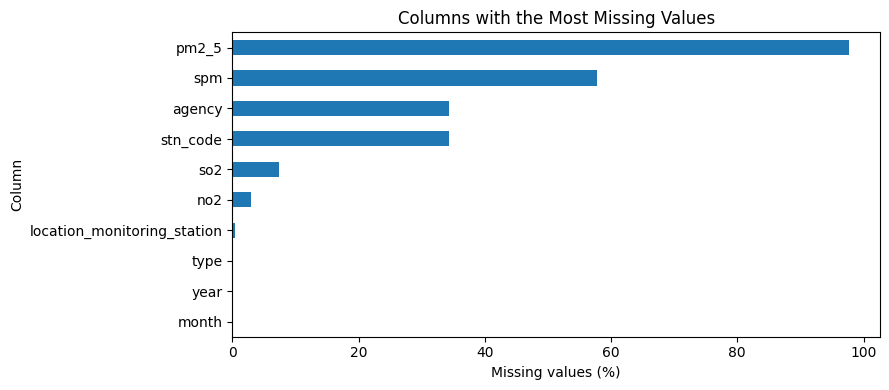

In [8]:
# Plot 1: columns with the most missing values
missing_percent = df.isnull().mean().sort_values(ascending=False) * 100

plt.figure(figsize=(9, 4))
missing_percent.head(10).sort_values().plot(kind="barh")
plt.title("Columns with the Most Missing Values")
plt.xlabel("Missing values (%)")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

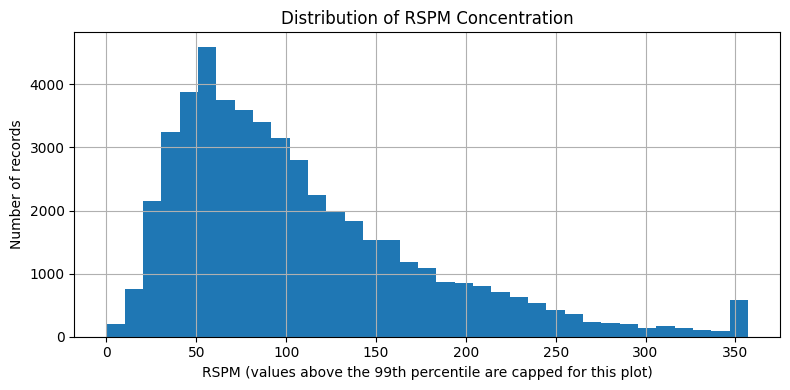

In [9]:
# Plot 2: distribution of RSPM values
# The display is capped at the 99th percentile so that extreme values
# do not make the rest of the distribution difficult to see.
upper_limit = df["rspm"].quantile(0.99)

plt.figure(figsize=(8, 4))
df["rspm"].clip(upper=upper_limit).hist(bins=35)
plt.title("Distribution of RSPM Concentration")
plt.xlabel("RSPM (values above the 99th percentile are capped for this plot)")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

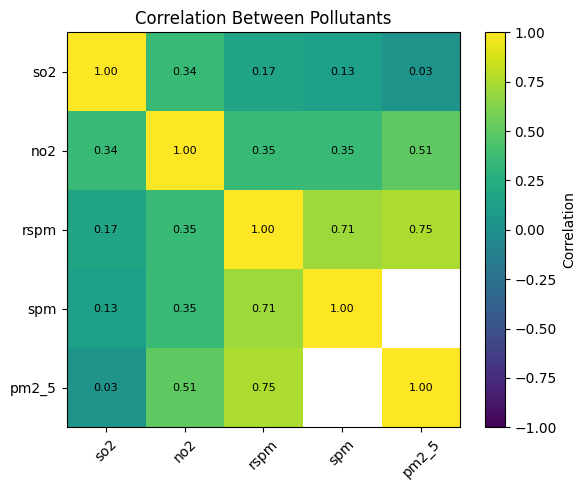

In [10]:
# Plot 3: correlation between available pollutant measurements
pollutants_available = [
    column for column in ["so2", "no2", "rspm", "spm", "pm2_5"]
    if column in df.columns
]

correlation = df[pollutants_available].corr()

plt.figure(figsize=(6, 5))
plt.imshow(correlation, vmin=-1, vmax=1, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(pollutants_available)), pollutants_available, rotation=45)
plt.yticks(range(len(pollutants_available)), pollutants_available)
plt.title("Correlation Between Pollutants")

for row in range(len(pollutants_available)):
    for col in range(len(pollutants_available)):
        value = correlation.iloc[row, col]
        if pd.notna(value):
            plt.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
# RSPM is the target column.
# Remove columns that are identifiers, descriptions, or the original date text.
columns_to_remove = [
    "rspm", "date", "sampling_date", "agency",
    "location_monitoring_station", "stn_code"
]

X = df.drop(columns=[col for col in columns_to_remove if col in df.columns])
y = df["rspm"]

# Convert text columns to numbers only when most values can be converted
for column in X.select_dtypes(include="object").columns:
    converted_column = pd.to_numeric(X[column], errors="coerce")

    if converted_column.notna().mean() > 0.85:
        X[column] = converted_column

# Remove columns that contain no usable values
X = X.dropna(axis=1, how="all")

# Remove rows that have no information in any input feature
usable_rows = X.notna().any(axis=1)
X = X.loc[usable_rows]
y = y.loc[usable_rows]

print("Input features:")
print(X.columns.tolist())
print("\nNumber of records available for modelling:", len(X))

In [ ]:
# 80% of the data is used for training and 20% for testing.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

In [ ]:
# Numeric columns: fill missing values with the median.
numeric_columns = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()

# Text columns: fill missing values with the most common value,
# then convert text categories into numeric columns.
categorical_columns = X_train.select_dtypes(exclude=["number", "bool"]).columns.tolist()

numeric_steps = Pipeline(steps=[
    ("fill_missing", SimpleImputer(strategy="median"))
])

categorical_steps = Pipeline(steps=[
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("convert_text", OneHotEncoder(handle_unknown="ignore"))
])

transform_steps = []

if numeric_columns:
    transform_steps.append(("numeric", numeric_steps, numeric_columns))

if categorical_columns:
    transform_steps.append(("categorical", categorical_steps, categorical_columns))

preprocessing = ColumnTransformer(transformers=transform_steps)

In [ ]:
# Linear Regression is the only machine-learning algorithm used in this notebook.
linear_regression_model = Pipeline(steps=[
    ("preprocessing", preprocessing),
    ("regression", LinearRegression())
])

linear_regression_model.fit(X_train, y_train)

print("Linear Regression model training completed.")

In [ ]:
# Predict RSPM values for records the model did not train on.
y_pred = linear_regression_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Linear Regression Model Results")
print("-------------------------------")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE):  {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R²): {r2:.3f}")

In [ ]:
# Show a small sample so the table is easy to read.
comparison = pd.DataFrame({
    "Actual RSPM": y_test.to_numpy(),
    "Predicted RSPM": y_pred
})

display(comparison.head(15).round(2))

# Plot actual versus predicted values
number_to_plot = min(2000, len(comparison))
plot_data = comparison.sample(number_to_plot, random_state=42)

plt.figure(figsize=(6, 6))
plt.scatter(plot_data["Actual RSPM"], plot_data["Predicted RSPM"], alpha=0.4)

lowest_value = min(plot_data["Actual RSPM"].min(), plot_data["Predicted RSPM"].min())
highest_value = max(plot_data["Actual RSPM"].max(), plot_data["Predicted RSPM"].max())

plt.plot([lowest_value, highest_value], [lowest_value, highest_value], "--")
plt.xlabel("Actual RSPM")
plt.ylabel("Predicted RSPM")
plt.title("Actual vs Predicted RSPM — Linear Regression")
plt.tight_layout()
plt.show()